# MobileNet – Oral Cancer Classification



In [1]:
import os
import json
import random
from glob import glob
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.applications.mobilenet import MobileNet, preprocess_input
from tensorflow.keras.callbacks import (
    EarlyStopping,
    LearningRateScheduler,
    ModelCheckpoint,
    ReduceLROnPlateau
)
from tensorflow.keras.layers import (
    BatchNormalization,
    Dense,
    Dropout,
    GlobalAveragePooling2D,
    Input
)
from tensorflow.keras.metrics import Precision, Recall
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 1. Configuration

In [2]:
SEED = 23
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Keep the same dataset structure used in the attached notebook.
OUTPUT_PATH = "Data_subsets"
TRAIN_PATH = os.path.join(OUTPUT_PATH, "train")
VAL_PATH = os.path.join(OUTPUT_PATH, "val")
TEST_PATH = os.path.join(OUTPUT_PATH, "test")

IMG_DIMS = 100
TARGET_SIZE = (IMG_DIMS, IMG_DIMS)
COLOR_MODE = "rgb"
CLASS_MODE = "categorical"
BATCH_SIZE = 16
EPOCHS = 7
ETA = 0.0001

MODEL_NAME = "MobileNet"
SAVE_STEM = "mobilenet"
BEST_MODEL_PATH = f"{SAVE_STEM}_best.keras"

for p in [TRAIN_PATH, VAL_PATH, TEST_PATH]:
    if not os.path.isdir(p):
        raise FileNotFoundError(
            f"Dataset folder not found: {p}\n"
            "Expected Data_subsets/train, Data_subsets/val and Data_subsets/test."
        )

print("Model:", MODEL_NAME)
print("Train:", TRAIN_PATH)
print("Validation:", VAL_PATH)
print("Test:", TEST_PATH)

Model: MobileNet
Train: Data_subsets\train
Validation: Data_subsets\val
Test: Data_subsets\test


## 2. Dataset inspection

Classes: ['CANCER', 'NON CANCER']
Training image counts: {'CANCER': 350, 'NON CANCER': 175}


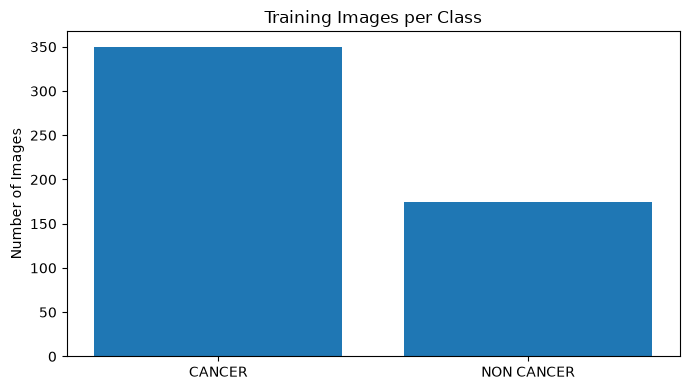

In [3]:
class_names = sorted([
    d for d in os.listdir(TRAIN_PATH)
    if os.path.isdir(os.path.join(TRAIN_PATH, d))
])
print("Classes:", class_names)

counts = {}
for cls in class_names:
    counts[cls] = len([
        f for f in os.listdir(os.path.join(TRAIN_PATH, cls))
        if os.path.isfile(os.path.join(TRAIN_PATH, cls, f))
    ])

print("Training image counts:", counts)

plt.figure(figsize=(7, 4))
plt.bar(list(counts.keys()), list(counts.values()))
plt.title("Training Images per Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

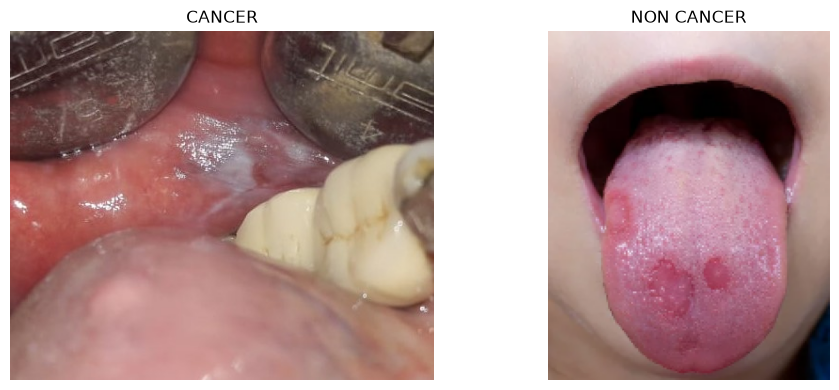

In [4]:
# Display one random training image from each class.
plt.figure(figsize=(10, 4))
for i, cls in enumerate(class_names):
    files = glob(os.path.join(TRAIN_PATH, cls, "*"))
    if not files:
        continue
    sample_path = random.choice(files)
    ax = plt.subplot(1, len(class_names), i + 1)
    plt.imshow(Image.open(sample_path).convert("RGB"))
    plt.title(cls)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 3. Data preprocessing and augmentation

In [5]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=5,
    width_shift_range=0.05,
    height_shift_range=0.05,
    brightness_range=[0.9, 1.1],
    zoom_range=[0.9, 1.1],
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=TARGET_SIZE,
    color_mode=COLOR_MODE,
    class_mode=CLASS_MODE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_gen = val_datagen.flow_from_directory(
    VAL_PATH,
    target_size=TARGET_SIZE,
    color_mode=COLOR_MODE,
    class_mode=CLASS_MODE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    seed=SEED
)

test_gen = test_datagen.flow_from_directory(
    TEST_PATH,
    target_size=TARGET_SIZE,
    color_mode=COLOR_MODE,
    class_mode=CLASS_MODE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    seed=SEED
)

print("Class indices:", train_gen.class_indices)

Found 525 images belonging to 2 classes.
Found 75 images belonging to 2 classes.
Found 150 images belonging to 2 classes.
Class indices: {'CANCER': 0, 'NON CANCER': 1}


## 4. Build MobileNet model

In [6]:
base_model = MobileNet(
    include_top=False,
    weights='imagenet',
    input_tensor=Input(shape=(IMG_DIMS, IMG_DIMS, 3)),
    input_shape=(IMG_DIMS, IMG_DIMS, 3)
)

C:\Users\sanja\AppData\Local\Temp\ipykernel_12156\2496078957.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNet(


In [7]:
# Freeze pretrained backbone for the first training stage.
for layer in base_model.layers:
    layer.trainable = False

num_classes = train_gen.num_classes

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    BatchNormalization(),
    Dense(512, activation="relu"),
    Dropout(0.4),
    BatchNormalization(),
    Dense(256, activation="relu"),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenet_1.00_224 (Functional)      │ (None, 3, 3, 1024)          │       3,228,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1024)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 1024)                │           4,096 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 2)                   │             514 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,891,650 (14.85 MB)

 Trainable params: 659,714 (2.52 MB)

 Non-trainable params: 3,231,936 (12.33 MB)

## 5. Compile and train

In [ ]:
METRICS = [
    "categorical_accuracy",
    Precision(name="precision"),
    Recall(name="recall")
]

model.compile(
    optimizer=Adam(learning_rate=ETA),
    loss="categorical_crossentropy",
    metrics=METRICS
)

cls_wt = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_gen.classes),
    y=train_gen.classes
)
class_weight = {i: float(w) for i, w in enumerate(cls_wt)}
print("Class weights:", class_weight)

def scheduler(epoch, lr):
    # Preserve the original learning-rate idea while remaining safe
    # if more epochs are used later.
    return ETA * 0.1 if epoch > 19 else ETA

callbacks = [
    LearningRateScheduler(scheduler),
    ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
]

history = model.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=val_gen,
    class_weight=class_weight,
    callbacks=callbacks
)

pd.DataFrame(history.history).to_csv(
    f"{SAVE_STEM}_training_history.csv",
    index=False
)

Class weights: {0: 0.75, 1: 1.5}
Epoch 1/7


C:\Users\sanja\anaconda3\envs\OC\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - categorical_accuracy: 0.6000 - loss: 0.7629 - precision: 0.6000 - recall: 0.6000
Epoch 1: val_loss improved from None to 0.34228, saving model to mobilenet_best.keras

Epoch 1: finished saving model to mobilenet_best.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 118s 3s/step - categorical_accuracy: 0.6000 - loss: 0.7629 - precision: 0.6000 - recall: 0.6000 - val_categorical_accuracy: 0.8533 - val_loss: 0.3423 - val_precision: 0.8533 - val_recall: 0.8533 - learning_rate: 1.0000e-04
Epoch 2/7
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 878ms/step - categorical_accuracy: 0.7714 - loss: 0.4781 - precision: 0.7714 - recall: 0.7714
Epoch 2: val_loss improved from 0.34228 to 0.27787, saving model to mobilenet_best.keras

Epoch 2: finished saving model to mobilenet_best.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - categorical_accuracy: 0.7714 - loss: 0.4781 - precision: 0.7714 - recall: 0.7714 - val_categorical_accuracy: 0.8933 - val_loss: 0.2779 - val_precision: 0.8933 - val_re

## 6. Training curves

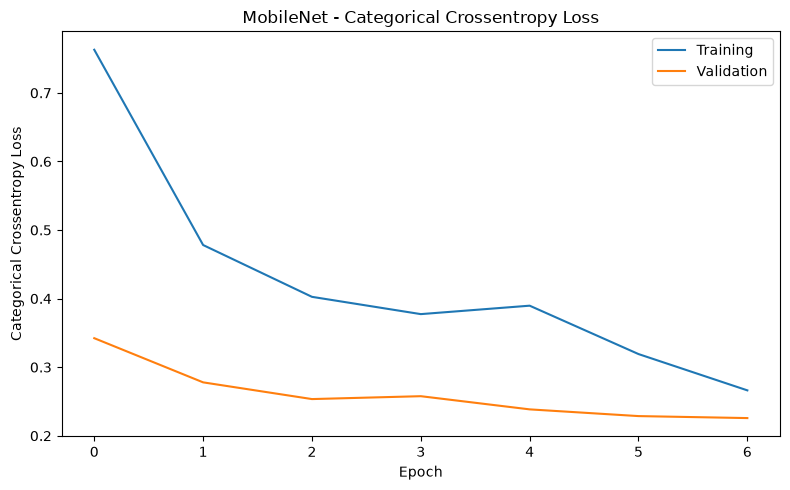

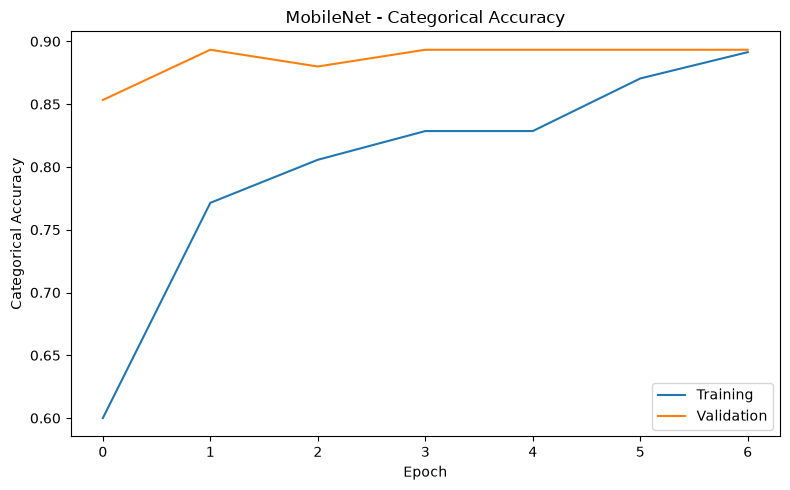

In [16]:
def plot_history(train_key, val_key, ylabel, filename):
    if train_key not in history.history or val_key not in history.history:
        print("Metric not available:", train_key, val_key)
        return
    plt.figure(figsize=(8, 5))
    plt.plot(history.history[train_key], label="Training")
    plt.plot(history.history[val_key], label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(f"{MODEL_NAME} - {ylabel}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=200)
    plt.show()

plot_history(
    "loss", "val_loss",
    "Categorical Crossentropy Loss",
    f"{SAVE_STEM}_loss.png"
)
plot_history(
    "categorical_accuracy", "val_categorical_accuracy",
    "Categorical Accuracy",
    f"{SAVE_STEM}_accuracy.png"
)

## 7. Test evaluation

In [17]:
# Always evaluate the best saved checkpoint.
best_model = load_model(BEST_MODEL_PATH)

test_gen.reset()
eval_values = best_model.evaluate(test_gen, verbose=1)
evaluation = dict(zip(best_model.metrics_names, eval_values))
print("Raw Keras evaluation:", evaluation)

test_gen.reset()
probabilities = best_model.predict(test_gen, verbose=1)
y_true = test_gen.classes
y_pred = np.argmax(probabilities, axis=1)

idx_to_class = {v: k for k, v in test_gen.class_indices.items()}
ordered_labels = list(range(len(idx_to_class)))
ordered_names = [idx_to_class[i] for i in ordered_labels]

report_dict = classification_report(
    y_true,
    y_pred,
    labels=ordered_labels,
    target_names=ordered_names,
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(report_dict).transpose()
display(report_df)
report_df.to_csv(f"{SAVE_STEM}_classification_report.csv")

overall_accuracy = accuracy_score(y_true, y_pred)
macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print(f"Accuracy       : {overall_accuracy:.4f}")
print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall   : {macro_recall:.4f}")
print(f"Macro F1-score : {macro_f1:.4f}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 464ms/step - categorical_accuracy: 0.8867 - loss: 0.3376 - precision: 0.8867 - recall: 0.8867
Raw Keras evaluation: {'loss': 0.33756932616233826, 'compile_metrics': 0.8866666555404663}
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 641ms/step


,precision,recall,f1-score,support
CANCER,0.966292,0.860000,0.910053,100.000000
NON CANCER,0.770492,0.940000,0.846847,50.000000
accuracy,0.886667,0.886667,0.886667,0.886667
macro avg,0.868392,0.900000,0.878450,150.000000
weighted avg,0.901025,0.886667,0.888984,150.000000


Accuracy       : 0.8867
Macro Precision: 0.8684
Macro Recall   : 0.9000
Macro F1-score : 0.8784


## 8. Confusion matrix

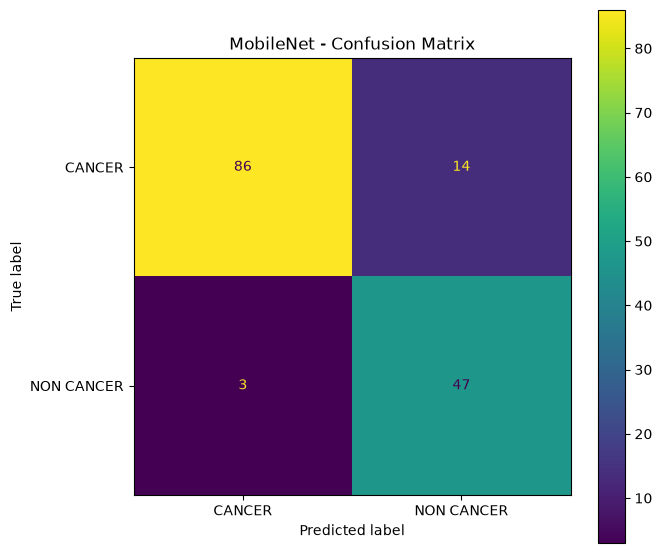

In [18]:
cm = confusion_matrix(y_true, y_pred, labels=ordered_labels)

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=ordered_names
)
disp.plot(ax=ax, values_format="d")
plt.title(f"{MODEL_NAME} - Confusion Matrix")
plt.tight_layout()
plt.savefig(f"{SAVE_STEM}_confusion_matrix.png", dpi=200)
plt.show()

## 9. Save standardized results for later comparison

In [19]:
results = {
    "model": MODEL_NAME,
    "image_size": [IMG_DIMS, IMG_DIMS],
    "batch_size": BATCH_SIZE,
    "epochs_requested": EPOCHS,
    "epochs_completed": len(history.history.get("loss", [])),
    "class_indices": train_gen.class_indices,
    "test_samples": int(test_gen.samples),
    "accuracy": float(overall_accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "best_model_path": BEST_MODEL_PATH
}

with open(f"{SAVE_STEM}_results.json", "w") as f:
    json.dump(results, f, indent=2)

print(json.dumps(results, indent=2))
print("\nSaved files:")
print(" -", BEST_MODEL_PATH)
print(" -", f"{SAVE_STEM}_results.json")
print(" -", f"{SAVE_STEM}_classification_report.csv")
print(" -", f"{SAVE_STEM}_training_history.csv")
print(" -", f"{SAVE_STEM}_confusion_matrix.png")

{
  "model": "MobileNet",
  "image_size": [
    100,
    100
  ],
  "batch_size": 16,
  "epochs_requested": 7,
  "epochs_completed": 7,
  "class_indices": {
    "CANCER": 0,
    "NON CANCER": 1
  },
  "test_samples": 150,
  "accuracy": 0.8866666666666667,
  "macro_precision": 0.8683919690550745,
  "macro_recall": 0.8999999999999999,
  "macro_f1": 0.8784498784498784,
  "best_model_path": "mobilenet_best.keras"
}

Saved files:
 - mobilenet_best.keras
 - mobilenet_results.json
 - mobilenet_classification_report.csv
 - mobilenet_training_history.csv
 - mobilenet_confusion_matrix.png


## 10. Single-image prediction

In [20]:
CLASS_NAMES = {v: k for k, v in train_gen.class_indices.items()}

def predict_image(image_path, show=True):
    img = tf.keras.utils.load_img(
        image_path,
        target_size=TARGET_SIZE
    )
    x = tf.keras.utils.img_to_array(img)
    x = np.expand_dims(x, axis=0)

    # IMPORTANT: use the same preprocessing function used in training.
    x = preprocess_input(x)

    probs = best_model.predict(x, verbose=0)[0]
    pred_index = int(np.argmax(probs))
    pred_class = CLASS_NAMES[pred_index]
    confidence = float(probs[pred_index]) * 100.0

    if show:
        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.axis("off")
        plt.title(
            f"{MODEL_NAME}: {pred_class} ({confidence:.2f}%)"
        )
        plt.show()

    print("Prediction :", pred_class)
    print("Confidence :", f"{confidence:.2f}%")
    print("Probabilities:", {
        CLASS_NAMES[i]: float(probs[i])
        for i in range(len(probs))
    })

    return pred_class, confidence, probs

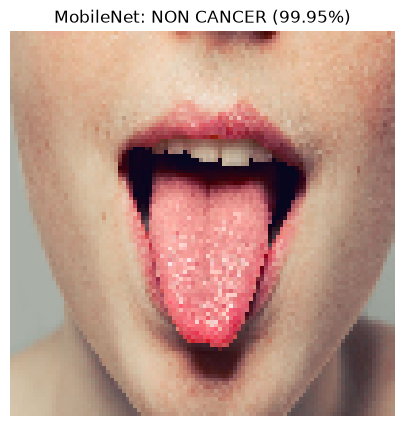

Prediction : NON CANCER
Confidence : 99.95%
Probabilities: {'CANCER': 0.0005051027983427048, 'NON CANCER': 0.9994949102401733}


('NON CANCER',
 99.94949102401733,
 array([5.051028e-04, 9.994949e-01], dtype=float32))

In [21]:

predict_image('./Data_subsets/test/NON CANCER/152.jpeg')


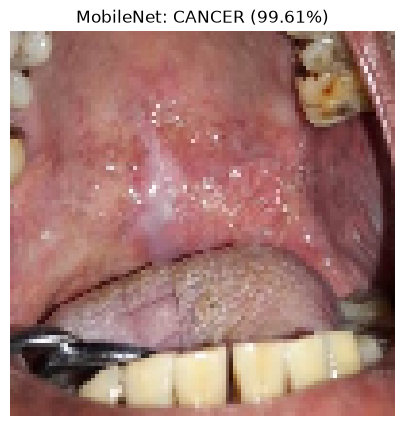

Prediction : CANCER
Confidence : 99.61%
Probabilities: {'CANCER': 0.9960675239562988, 'NON CANCER': 0.003932460676878691}


('CANCER', 99.60675239562988, array([0.9960675 , 0.00393246], dtype=float32))

In [22]:
predict_image('./Data_subsets/test/CANCER/221.jpeg')